# Lab 5 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab05.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.


In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import torch
import lab05

NPZ = '../data/parts_shapes.npz'
X, y = lab05.load_data(NPZ)
CLASSES = [str(c) for c in np.load(NPZ, allow_pickle=False)['classes']]
results = lab05.run_experiment(X, y)
results

{'baseline': {'accuracy': 0.2573, 'trainable_params': 0},
 'scratch': {'accuracy': 0.824, 'trainable_params': 7940},
 'transfer': {'accuracy': 0.9469, 'trainable_params': 2052}}

## Plot 1 — What the images look like

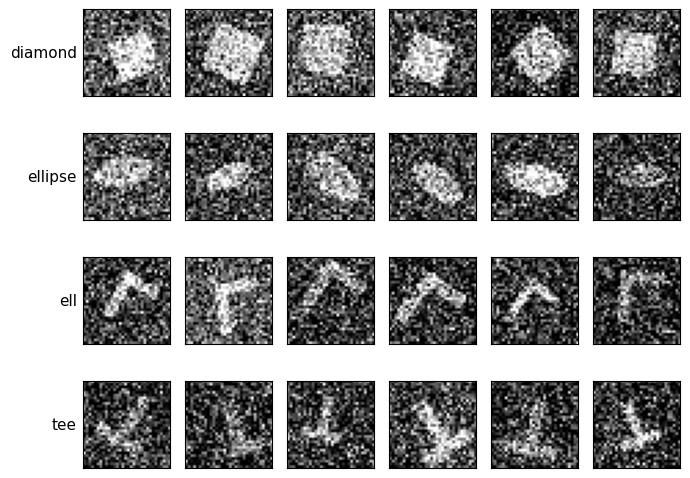

In [2]:
# ============ Plot 1 ============
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(7, 1.3 * len(CLASSES)))
for c in range(len(CLASSES)):
    idx = torch.where(y == c)[0][:6]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X[i, 0], cmap='gray', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    axes[c, 0].set_ylabel(CLASSES[c], rotation=0, ha='right', va='center', fontsize=11)
fig.tight_layout()
fig.savefig('fig1_samples.png', dpi=200, bbox_inches='tight')
plt.show()


## Plot 2 — How the gap depends on the number of labels

scratch  {60: 0.4377, 120: 0.6491, 240: 0.824, 480: 0.9014, 900: 0.9667}
transfer {60: 0.7439, 120: 0.8907, 240: 0.9469, 480: 0.9681, 900: 0.98}


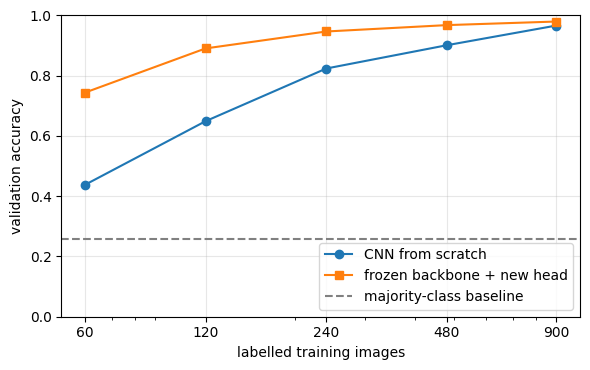

In [3]:
# ============ Plot 2 ============
budgets = [60, 120, 240, 480, 900]
acc_s, acc_t = [], []
for n in budgets:
    X_tr, X_val, y_tr, y_val = lab05.split_data(X, y, n_train=n)
    for build, store in ((lambda: lab05.build_cnn(lab05.N_CLASSES), acc_s),
                         (lambda: lab05.build_transfer_model(lab05.N_CLASSES, '../data/backbone_shapes6.pt'), acc_t)):
        lab05.set_seed()
        m = lab05.train_model(build(), X_tr, y_tr)
        store.append(lab05.accuracy(y_val, lab05.predict(m, X_val)))
print('scratch ', dict(zip(budgets, acc_s)))
print('transfer', dict(zip(budgets, acc_t)))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(budgets, acc_s, 'o-', label='CNN from scratch')
ax.plot(budgets, acc_t, 's-', label='frozen backbone + new head')
ax.axhline(results['baseline']['accuracy'], ls='--', color='gray', label='majority-class baseline')
ax.set_xscale('log'); ax.set_xticks(budgets); ax.set_xticklabels(budgets)
ax.set_xlabel('labelled training images'); ax.set_ylabel('validation accuracy')
ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('fig2_budget.png', dpi=200, bbox_inches='tight')
plt.show()


## Plot 3 — Which classes get confused

CNN from scratch 0.824
[[205  31   0   3]
 [ 74 153   3   1]
 [ 11   6 226   4]
 [ 17   7  12 207]]
frozen backbone + new head 0.9469
[[227  10   0   2]
 [  9 220   1   1]
 [  1   7 238   1]
 [  2  12   5 224]]


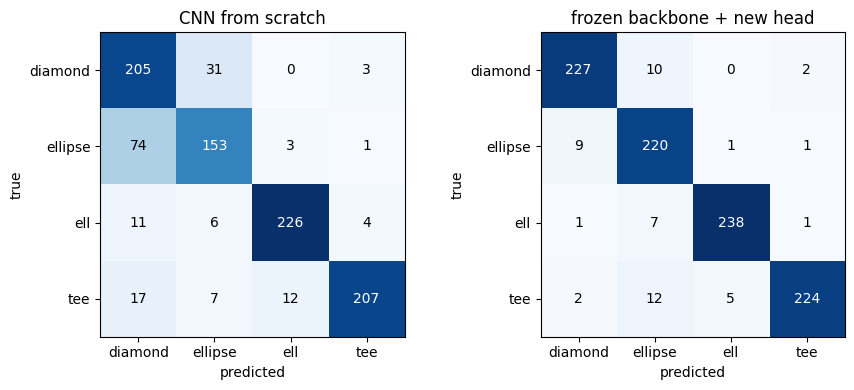

In [4]:
# ============ Plot 3 ============
X_tr, X_val, y_tr, y_val = lab05.split_data(X, y)
k = len(CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, build) in zip(axes, (('CNN from scratch', lambda: lab05.build_cnn(lab05.N_CLASSES)),
                                    ('frozen backbone + new head', lambda: lab05.build_transfer_model(lab05.N_CLASSES, '../data/backbone_shapes6.pt')))):
    lab05.set_seed()
    m = lab05.train_model(build(), X_tr, y_tr)
    pred = lab05.predict(m, X_val)
    cm = torch.zeros(k, k, dtype=torch.long)
    for t, p in zip(y_val, pred):
        cm[t, p] += 1
    print(title, lab05.accuracy(y_val, pred)); print(cm.numpy())
    ax.imshow(cm, cmap='Blues')
    for i in range(k):
        for j in range(k):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(k)); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(k)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title)
fig.tight_layout()
fig.savefig('fig3_confusion.png', dpi=200, bbox_inches='tight')
plt.show()
